# Diagnostics on the smoke run

Reads a cached run (`data/cache/*_<RUN>.npz`) and the model exported with it. Set `DIAG_RUN` (default `v1_r2`; `smoke_r1` = the first smoke run in the planning repo). No downloads, no training, a few minutes on a laptop. Run from `ml/`.

- D0: planet check baseline
- D1: which features give the planet away
- D2: Earth subsets (FABDEM preview) and the flat-ground noise floor
- D3: what blurring does to the noise floor
- D4: does normalising or dropping features close the gap without killing region info
- D5: library yield (south pole, Mars clustering, stripes)
- D6: how noisy the smoke scores are
- D7: correlated features
- D8: why analog sites rank badly on landscape
- D9: analog-site coordinates that look wrong
- Summary table at the end

In [1]:
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.special import expit
from scipy.stats import rankdata, spearmanr

assert Path.cwd().name == "ml", "run from the ml/ folder"
import os
RUN = os.environ.get("DIAG_RUN", "v1_r2")                # "<profile>_<cache tag>" of the run to look at
if RUN == "smoke_r1":                                     # the first smoke run, kept in the planning repo
    PLAN = Path.cwd().parents[1] / "spaceapps_planning"
    CACHE, EXPORT = PLAN / "data" / "cache", PLAN / "export"
else:
    CACHE, EXPORT = Path.cwd().parent / "data" / "cache", Path.cwd() / "export"
sys.path.insert(0, str(EXPORT))
import analog_runtime as rt

model = rt.load(EXPORT / "model.npz")
LIB = {w: dict(np.load(CACHE / f"library_{w}_{RUN}.npz")) for w in rt.WORLDS}
E = dict(np.load(CACHE / f"earth_{RUN}.npz"))
SCALES, F, NQ = model.scales, list(rt.TOKEN_FEATURES), len(rt.QUANTILES)
B = list(rt.BLOCK_FEATURES)
CRATER_TAGS = ["small_crater", "crater_rim", "crater_floor"]
SUMMARY = {}
pd.set_option("display.width", 180, "display.max_columns", 40, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

lib = {k: np.concatenate([LIB[w][k] for w in rt.WORLDS]).astype(str if LIB["moon"][k].dtype.kind == "U" else float)
       for k in ("world", "region", "tag", "lat", "lon", "stripe", "href", "native_m", "group", "name")}
tok = {s: {w: LIB[w][f"tokens_{s}"] / model.S[s]["scale"] for w in rt.WORLDS} | {"earth": E[f"tokens_{s}"] / model.S[s]["scale"]}
       for s in SCALES}
blk = {s: {w: LIB[w][f"block_{s}"] for w in rt.WORLDS} | {"earth": E[f"block_{s}"]} for s in SCALES}
raw = {s: {w: LIB[w][f"tokens_{s}"] for w in rt.WORLDS} | {"earth": E[f"tokens_{s}"]} for s in SCALES}
env = pd.DataFrame({k: E[k] for k in ("name", "lat", "lon", "set", "split", "tag", "tree", "crop", "built", "water", "snow", "bare", "precip")})
for k in ("name", "set", "split", "tag"):
    env[k] = env[k].astype(str)
RAND = (env["set"] == "random").values
covered = env[["tree", "built"]].fillna(0).sum(1).values
print("library:", dict(Counter(lib["world"])), "| earth:", dict(Counter(env["set"])))
print("regions:", dict(Counter(zip(lib["world"], lib["region"]))))
print("tags:", dict(Counter(lib["tag"])))
print("NaN token rows, earth:", {s: int(np.isnan(tok[s]["earth"]).any((1, 2)).sum()) for s in SCALES})

library: {np.str_('moon'): 2236, np.str_('mars'): 2400} | earth: {'random': 2500, 'analog': 56, 'featured': 9, 'crater': 40, 'volcano': 250}
regions: {(np.str_('moon'), np.str_('maria')): 600, (np.str_('moon'), np.str_('highlands')): 540, (np.str_('moon'), np.str_('basins')): 496, (np.str_('moon'), np.str_('south_pole')): 600, (np.str_('mars'), np.str_('highlands')): 600, (np.str_('mars'), np.str_('lowlands')): 600, (np.str_('mars'), np.str_('volcanic')): 600, (np.str_('mars'), np.str_('outflow')): 600}
tags: {np.str_('background'): 2892, np.str_('graben'): 179, np.str_('wrinkle_ridge'): 225, np.str_('crater_chain'): 70, np.str_('small_crater'): 209, np.str_('crater_floor'): 193, np.str_('massif'): 110, np.str_('sinuous_rille'): 88, np.str_('crater_rim'): 209, np.str_('volcanic_edifice'): 103, np.str_('canyon'): 58, np.str_('mesa'): 77, np.str_('scarp'): 62, np.str_('channel'): 73, np.str_('chaos'): 35, np.str_('lava_flow'): 25, np.str_('yardang'): 28}
NaN token rows, earth: {'site': 0

/var/folders/t0/mtw80r2115v6pd9wky_yrfzh0000gn/T/ipykernel_86334/2774985238.py:44: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  covered = env[["tree", "built"]].fillna(0).sum(1).values


In [2]:
# shared helpers
def sk(t):
    return rt.sketch_raw(np.asarray(t, dtype=np.float64))


def cols(features):
    # sketch layout is quantile-major: column = q * 13 + feature
    return np.array([q * len(F) + F.index(f) for f in features for q in range(NQ)])


def pca(s, X):
    P = model.S[s]
    return (X - P["pca_mean"]) @ P["pca_comp"].T


def planet_check(X, k=5, reps=30, seed=0):
    # balanced subsample per world, leave-one-out 5-NN vote. 1/len(X) = can't tell the worlds apart
    r = np.random.default_rng(seed)
    names = list(X)
    n = min(min(len(v) for v in X.values()), 600)   # cap so the distance matrix stays small at v1 size
    acc, conf = [], np.zeros((len(names), len(names)))
    for _ in range(reps):
        Xs = np.concatenate([v[r.choice(len(v), n, replace=False)] for v in X.values()])
        y = np.repeat(np.arange(len(names)), n)
        D = ((Xs[:, None] - Xs[None]) ** 2).sum(-1)
        np.fill_diagonal(D, np.inf)
        nb = y[np.argsort(D, 1)[:, :k]]
        g = np.array([np.bincount(row, minlength=len(names)).argmax() for row in nb])
        acc.append((g == y).mean())
        np.add.at(conf, (y, g), 1)
    return float(np.mean(acc)), float(np.std(acc)), pd.DataFrame(conf / conf.sum(1, keepdims=True), names, names), n


def region_proxy(Xlib, world, k=5):
    # 5-NN region vote inside one world, never using blocks from the same group. stand-in for region info
    m = lib["world"] == world
    reg, grp, Xw = lib["region"][m], lib["group"][m], Xlib[m]
    ok = np.isin(reg, [r for r, c in Counter(reg).items() if c >= 5])
    reg, grp, Xw = reg[ok], grp[ok], Xw[ok]
    D = ((Xw[:, None] - Xw[None]) ** 2).sum(-1)
    D[grp[:, None] == grp[None]] = np.inf
    nb = reg[np.argsort(D, 1)[:, :k]]
    g = np.array([Counter(row).most_common(1)[0][0] for row in nb])
    return float(np.mean([np.mean(g[reg == r] == r) for r in np.unique(reg)])), 1 / len(np.unique(reg))


def cross_proxy(Xlib, Xearth, k=10):
    # Earth craters -> share of crater-tagged blocks among the 10 nearest Moon blocks;
    # Earth volcanoes -> share of Mars volcanic-region blocks among the 10 nearest Mars blocks
    moon, mars = lib["world"] == "moon", lib["world"] == "mars"
    is_cr = np.isin(lib["tag"][moon], CRATER_TAGS)
    is_vo = lib["region"][mars] == "volcanic"
    near = lambda x, m: np.argsort(((Xlib[m] - x) ** 2).sum(1))[:k]
    cr = np.mean([is_cr[near(x, moon)].mean() for x in Xearth[(env["set"] == "crater").values]])
    vo = np.mean([is_vo[near(x, mars)].mean() for x in Xearth[(env["set"] == "volcano").values]])
    return dict(crater=cr, crater_base=is_cr.mean(), volcano=vo, volcano_base=is_vo.mean())


def auc(a, b):
    r = rankdata(np.r_[a, b])
    return (r[:len(a)].sum() - len(a) * (len(a) + 1) / 2) / (len(a) * len(b))


def lib_all(d):
    return np.concatenate([d[w] for w in rt.WORLDS])

## D0. Planet check baseline

Same idea as the notebook: can a block's sketch alone tell you which world it's from? Moon, Mars and random Earth land, balanced, 5 nearest neighbours. 0.33 = can't tell. The smoke notebook reported 0.80 (site) and 0.77 (regional). "raw sketch" skips the PCA step and is what D1 to D4 use.

In [3]:
rows = []
for s in SCALES:
    for kind in ("model sketch (PCA)", "raw sketch"):
        f = (lambda X, s=s: pca(s, sk(X))) if kind.startswith("model") else sk
        X = {w: f(tok[s][w]) for w in rt.WORLDS} | {"earth": f(tok[s]["earth"][RAND])}
        acc, sd, conf, n = planet_check(X)
        rows.append(dict(scale=s, sketch=kind, accuracy=acc, sd=sd, n_per_world=n,
                         **{f"recall {w}": conf.loc[w, w] for w in conf.index}))
        if kind.startswith("model"):
            SUMMARY[f"planet check, {s}"] = (acc, "0.33 blind; aim < 0.5")
d0 = pd.DataFrame(rows)
d0

,scale,sketch,accuracy,sd,n_per_world,recall moon,recall mars,recall earth
0,site,model sketch (PCA),0.699,0.009,600,0.845,0.578,0.674
1,site,raw sketch,0.699,0.010,600,0.845,0.579,0.673
2,regional,model sketch (PCA),0.678,0.012,600,0.796,0.552,0.686
3,regional,raw sketch,0.677,0.013,600,0.796,0.550,0.685


## D1. Which features give the planet away

For each feature: planet check using only that feature ("alone"), and with everything except it ("without"). Plus how separable the per-block average is for each pair of worlds (AUC: 0.5 = same distribution, 0 or 1 = fully separate). Block features are checked one at a time. The features at the top are the ones to fix first.


site scale, all token features together: 0.70


,feature,kind,alone,without,auc_earth_moon,auc_earth_mars,auc_moon_mars,earth_vs_planets
0,rough_coarse,token,0.658,0.632,0.454,0.408,0.405,1.415
1,shadow_low,token,0.574,0.691,0.375,0.404,0.559,0.775
2,slope_mean,token,0.552,0.696,0.309,0.368,0.594,0.823
3,geo_concave,token,0.544,0.695,0.358,0.409,0.586,0.782
4,geo_convex,token,0.497,0.691,0.307,0.420,0.658,0.720
5,shadow_mid,token,0.447,0.708,0.323,0.417,0.604,1.033
6,relief,block,0.436,NaN,0.242,0.332,0.621,0.792
7,hurst,block,0.423,NaN,0.205,0.369,0.670,0.880
8,depression_depth,block,0.378,NaN,0.305,0.348,0.556,0.348
9,norm_height,token,0.373,0.712,0.390,0.432,0.544,0.925



regional scale, all token features together: 0.68


,feature,kind,alone,without,auc_earth_moon,auc_earth_mars,auc_moon_mars,earth_vs_planets
0,rough_coarse,token,0.587,0.654,0.161,0.400,0.843,0.560
1,slope_mean,token,0.575,0.673,0.132,0.366,0.821,0.411
2,shadow_low,token,0.574,0.677,0.194,0.395,0.814,0.578
3,shadow_mid,token,0.550,0.674,0.134,0.355,0.826,0.391
4,geo_concave,token,0.545,0.674,0.191,0.389,0.756,0.627
5,relief,block,0.522,NaN,0.081,0.307,0.803,0.755
6,geo_convex,token,0.506,0.672,0.201,0.361,0.706,0.617
7,depression_depth,block,0.441,NaN,0.178,0.224,0.531,0.128
8,depression_area,block,0.436,NaN,0.207,0.250,0.539,0.248
9,hurst,block,0.429,NaN,0.219,0.286,0.580,0.864


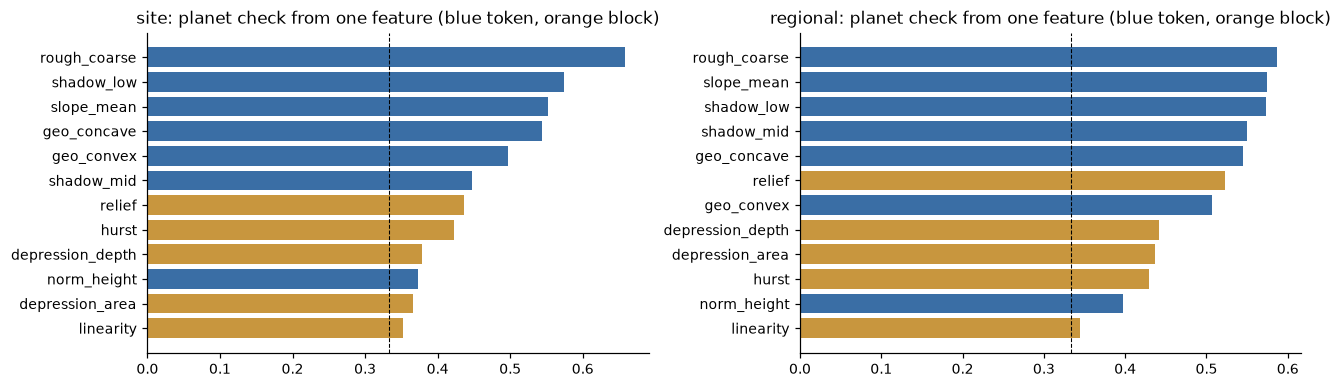

In [4]:
D1 = {}
for s in SCALES:
    Xfull = {w: sk(tok[s][w]) for w in rt.WORLDS} | {"earth": sk(tok[s]["earth"][RAND])}
    base = planet_check(Xfull)[0]
    rows = []
    for f in F:
        c, keep = cols([f]), np.setdiff1d(np.arange(len(F) * NQ), cols([f]))
        mean = {w: tok[s][w][..., F.index(f)].mean(1) for w in rt.WORLDS} | {"earth": tok[s]["earth"][RAND][..., F.index(f)].mean(1)}
        rows.append(dict(feature=f, kind="token",
                         alone=planet_check({w: v[:, c] for w, v in Xfull.items()})[0],
                         without=planet_check({w: v[:, keep] for w, v in Xfull.items()})[0],
                         auc_earth_moon=auc(mean["earth"], mean["moon"]), auc_earth_mars=auc(mean["earth"], mean["mars"]),
                         auc_moon_mars=auc(mean["moon"], mean["mars"]),
                         earth_vs_planets=mean["earth"].mean() / max(np.r_[mean["moon"], mean["mars"]].mean(), 1e-9)))
    for j, b in enumerate(B):
        v = {w: blk[s][w][:, j] for w in rt.WORLDS} | {"earth": blk[s]["earth"][RAND][:, j]}
        if b == "relief":
            v = {w: np.log1p(np.maximum(x, 0)) for w, x in v.items()}
        pool = np.concatenate(list(v.values()))
        iqr = np.subtract(*np.nanpercentile(pool, [75, 25])) or 1.0
        rows.append(dict(feature=b, kind="block", alone=planet_check({w: (x / iqr)[:, None] for w, x in v.items()})[0],
                         without=np.nan, auc_earth_moon=auc(v["earth"], v["moon"]), auc_earth_mars=auc(v["earth"], v["mars"]),
                         auc_moon_mars=auc(v["moon"], v["mars"]),
                         earth_vs_planets=np.nanmean(v["earth"]) / max(np.nanmean(np.r_[v["moon"], v["mars"]]), 1e-9)))
    D1[s] = pd.DataFrame(rows).sort_values("alone", ascending=False).reset_index(drop=True)
    print(f"\n{s} scale, all token features together: {base:.2f}")
    display(D1[s])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, s in zip(axes, SCALES):
    d = D1[s]
    ax.barh(d["feature"], d["alone"], color=np.where(d["kind"] == "token", "#3a6ea5", "#c8963e"))
    ax.axvline(1 / 3, color="k", lw=0.7, ls="--")
    ax.invert_yaxis()
    ax.set_title(f"{s}: planet check from one feature (blue token, orange block)")
plt.tight_layout(); plt.show()

## D2. Earth subsets (a cheap preview of FABDEM) and the flat-ground noise floor

FABDEM only changes Earth where there are trees and buildings. So if the planet check drops a lot when Earth is limited to bare blocks, trees and buildings are the problem and FABDEM helps. If it stays high on bare ground, the gap is the instrument (radar vs stereo) or real physics, and FABDEM alone won't close it.

The second table looks at fine roughness on nearly flat cells (mean slope under 2°). On flat ground, fine roughness is mostly DEM noise, so this is each source's noise floor in metres.

,scale,earth_subset,n_earth,n_used,accuracy,sd,earth_recall
0,site,"random, all",2500,600,0.699,0.010,0.673
1,site,"random, tree+built < 5%",1197,600,0.734,0.009,0.730
2,site,"random, tree > 30%",916,600,0.679,0.010,0.663
3,site,"any set, tree+built < 5%",1400,600,0.730,0.008,0.728
4,site,analog sites,56,56,0.633,0.040,0.617
5,regional,"random, all",2500,600,0.677,0.013,0.685
6,regional,"random, tree+built < 5%",1197,600,0.676,0.012,0.660
7,regional,"random, tree > 30%",916,600,0.707,0.010,0.777
8,regional,"any set, tree+built < 5%",1400,600,0.667,0.014,0.642
9,regional,analog sites,56,56,0.617,0.036,0.584


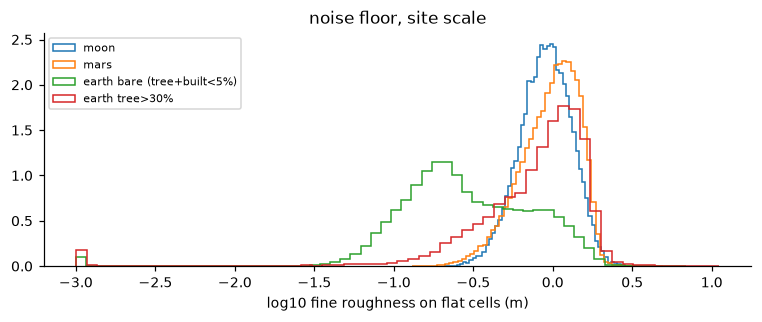

,source,flat_cells,median_m,p90_m,share_of_cells_flat
0,moon,35525,0.910,1.440,0.248
1,mars,50626,1.016,1.563,0.330
2,earth bare (tree+built<5%),57066,0.257,1.030,0.637
3,earth tree>30%,16004,0.925,1.605,0.242


In [5]:
subsets = {
    "random, all": RAND,
    "random, tree+built < 5%": RAND & (covered < 0.05),
    "random, tree > 30%": RAND & (env["tree"].fillna(0).values > 0.3),
    "any set, tree+built < 5%": covered < 0.05,
    "analog sites": (env["set"] == "analog").values,
}
rows = []
for s in SCALES:
    for name, m in subsets.items():
        if m.sum() < 15:
            continue
        X = {w: sk(tok[s][w]) for w in rt.WORLDS} | {"earth": sk(tok[s]["earth"][m])}
        acc, sd, conf, n = planet_check(X)
        rows.append(dict(scale=s, earth_subset=name, n_earth=int(m.sum()), n_used=n, accuracy=acc, sd=sd, earth_recall=conf.loc["earth", "earth"]))
d2 = pd.DataFrame(rows)
display(d2)
for s in SCALES:
    a = d2[(d2.scale == s)].set_index("earth_subset")["accuracy"]
    SUMMARY[f"planet check {s}, bare Earth only"] = (a.get("random, tree+built < 5%", np.nan), "big drop vs all = FABDEM helps")

i_s, i_r = F.index("slope_mean"), F.index("rough_fine" if "rough_fine" in F else "rough_coarse")   # v1.1 dropped rough_fine
groups = {"moon": raw["site"]["moon"], "mars": raw["site"]["mars"],
          "earth bare (tree+built<5%)": raw["site"]["earth"][covered < 0.05],
          "earth tree>30%": raw["site"]["earth"][env["tree"].fillna(0).values > 0.3]}
rows, fig, ax = [], plt.figure(figsize=(7, 3)), plt.gca()
for name, t in groups.items():
    c = t.reshape(-1, len(F))
    flat = c[c[:, i_s] < 2.0, i_r]
    rows.append(dict(source=name, flat_cells=len(flat), median_m=np.median(flat), p90_m=np.percentile(flat, 90),
                     share_of_cells_flat=len(flat) / len(c)))
    ax.hist(np.log10(flat + 1e-3), bins=60, histtype="step", density=True, label=name)
ax.set_xlabel("log10 fine roughness on flat cells (m)"); ax.legend(fontsize=7); ax.set_title("noise floor, site scale")
plt.tight_layout(); plt.show()
d2b = pd.DataFrame(rows)
d2b

## D3. What blurring does to the noise floor

Uses the stored height grids (library blocks and the Earth blocks that kept one) and recomputes fine roughness on flat cells at different blur widths. The runtime currently blurs by 1 px. If the Earth/Moon/Mars ratios get close to 1 at 2 px while the slope of real terrain barely changes, a small blur is cheap. If slope p90 drops a lot, blurring is throwing away real terrain and we skip it.

In [6]:
def floor_stats(dems, sigma, res=rt.SCALES["site"]["res"]):
    fl, sl = [], []
    for z in dems:
        z = rt.fill_nans(np.asarray(z, dtype=np.float64))
        if sigma > 0:
            z = ndimage.gaussian_filter(z, sigma, mode="nearest")
        rf = z - ndimage.uniform_filter(z, rt.ROUGH_FINE_PX, mode="nearest")
        slope = rt.slope_deg(z, res)
        S, RF = rt.to_cells(slope[8:-8, 8:-8], 14), rt.to_cells(rf[8:-8, 8:-8], 14)
        m, r = S.mean(1), np.sqrt((RF ** 2).mean(1))
        fl.append(r[m < 2.0]); sl.append(np.percentile(S, 90, axis=1))
    return np.median(np.concatenate(fl)) if fl else np.nan, np.median(np.concatenate(sl))


e_dem = E["dem_site"][:, rt.PAD_PX:-rt.PAD_PX, rt.PAD_PX:-rt.PAD_PX]
e_rows = E["dem_index"]
dem_sets = {"moon": LIB["moon"]["dem_site"], "mars": LIB["mars"]["dem_site"],
            "earth bare": e_dem[covered[e_rows] < 0.05], "earth tree>30%": e_dem[env["tree"].fillna(0).values[e_rows] > 0.3]}
print({k: len(v) for k, v in dem_sets.items()}, "| earth blocks with a stored grid come from sets:", dict(Counter(env["set"].values[e_rows])))
rows = []
for sigma in (0.0, 1.0, 1.5, 2.0, 3.0):
    st = {k: floor_stats(v, sigma) for k, v in dem_sets.items() if len(v)}
    rows.append(dict(blur_px=sigma, **{f"floor {k}": v[0] for k, v in st.items()},
                     **{f"slope_p90 {k}": v[1] for k, v in st.items()}))
d3 = pd.DataFrame(rows).set_index("blur_px")
for k in ("moon", "mars"):
    d3[f"earth bare / {k}"] = d3["floor earth bare"] / d3[f"floor {k}"]
d3

{'moon': 2236, 'mars': 2400, 'earth bare': 86, 'earth tree>30%': 7} | earth blocks with a stored grid come from sets: {'analog': 56, 'featured': 9, 'crater': 40}


,floor moon,floor mars,floor earth bare,floor earth tree>30%,slope_p90 moon,slope_p90 mars,slope_p90 earth bare,slope_p90 earth tree>30%,earth bare / moon,earth bare / mars
blur_px,,,,,,,,,,
0.0,0.124,0.211,0.187,0.437,7.169,5.703,7.531,11.129,1.507,0.889
1.0,0.095,0.150,0.077,0.155,6.892,4.827,6.372,8.838,0.813,0.512
1.5,0.078,0.110,0.053,0.090,6.652,4.225,5.799,8.328,0.670,0.477
2.0,0.064,0.079,0.040,0.063,6.416,3.729,5.339,7.784,0.619,0.500
3.0,0.042,0.043,0.026,0.034,5.944,3.043,4.517,6.796,0.615,0.602


## D4. Does a feature fix close the gap without killing region info?

Features are taken in D1 order (most planet-revealing first). For k = 0 to 13 we either convert the top k features to within-world percentiles ("normalise", keeps each block's ranking inside its own world) or remove them ("drop"). For each step:

- planet: planet check (want it falling toward 0.33)
- region moon / region mars: 5-NN region vote inside each world, holding out whole groups (want it to stay up)
- crater / volcano: Earth craters near crater-tagged Moon blocks, Earth volcanoes near Mars's volcanic region (want them above their base rates)

These are sketch-level stand-ins, not the trained model, so read them as directions, not final numbers.


site scale. chance: planet 0.33, region moon 0.25, region mars 0.25


,how,k,last_added,planet,region_moon,region_mars,crater,crater_base,volcano,volcano_base
0,normalise,0,-,0.699,0.460,0.373,0.155,0.156,0.146,0.25
1,normalise,1,rough_coarse,0.737,0.452,0.367,0.135,0.156,0.174,0.25
2,normalise,2,shadow_low,0.777,0.450,0.364,0.155,0.156,0.173,0.25
3,normalise,3,slope_mean,0.784,0.452,0.364,0.148,0.156,0.167,0.25
4,normalise,4,geo_concave,0.793,0.449,0.372,0.150,0.156,0.168,0.25
5,normalise,5,geo_convex,0.780,0.464,0.363,0.173,0.156,0.167,0.25
6,normalise,6,shadow_mid,0.782,0.480,0.359,0.133,0.156,0.147,0.25
7,normalise,7,norm_height,0.783,0.475,0.359,0.148,0.156,0.150,0.25
8,drop,0,-,0.699,0.460,0.373,0.155,0.156,0.146,0.25
9,drop,1,rough_coarse,0.632,0.472,0.359,0.145,0.156,0.176,0.25



regional scale. chance: planet 0.33, region moon 0.25, region mars 0.25


,how,k,last_added,planet,region_moon,region_mars,crater,crater_base,volcano,volcano_base
0,normalise,0,-,0.677,0.604,0.459,0.035,0.156,0.207,0.25
1,normalise,1,rough_coarse,0.892,0.600,0.480,0.120,0.156,0.205,0.25
2,normalise,2,slope_mean,0.933,0.617,0.485,0.128,0.156,0.211,0.25
3,normalise,3,shadow_low,0.933,0.607,0.489,0.198,0.156,0.196,0.25
4,normalise,4,shadow_mid,0.933,0.613,0.471,0.120,0.156,0.172,0.25
5,normalise,5,geo_concave,0.935,0.611,0.477,0.155,0.156,0.175,0.25
6,normalise,6,geo_convex,0.939,0.618,0.473,0.148,0.156,0.184,0.25
7,normalise,7,norm_height,0.938,0.624,0.476,0.152,0.156,0.183,0.25
8,drop,0,-,0.677,0.604,0.459,0.035,0.156,0.207,0.25
9,drop,1,rough_coarse,0.654,0.566,0.470,0.055,0.156,0.210,0.25


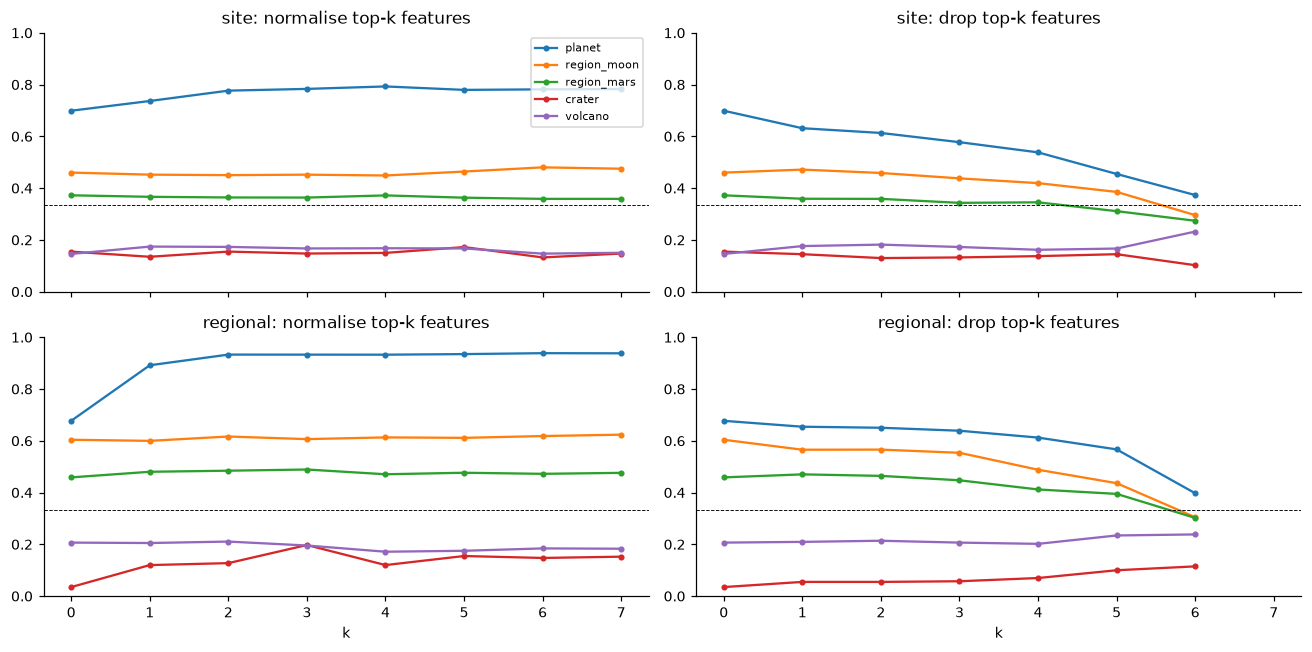

In [7]:
def world_pct(T, ref, fs):
    # map the chosen features to their percentile within a reference pool of that world's cells (x2 so the IQR is ~1)
    T = T.copy()
    for f in fs:
        j = F.index(f)
        pool = np.sort(ref[..., j].ravel())
        T[..., j] = 2.0 * np.searchsorted(pool, T[..., j]) / len(pool)
    return T


def variant(s, fs, how):
    t = {w: tok[s][w] for w in rt.WORLDS} | {"earth": tok[s]["earth"]}
    if how == "normalise" and fs:
        t = {w: world_pct(v, (v if w != "earth" else tok[s]["earth"][RAND]), fs) for w, v in t.items()}
    keep = cols([f for f in F if f not in fs]) if how == "drop" else np.arange(len(F) * NQ)
    X = {w: sk(v)[:, keep] for w, v in t.items()}
    Xlib = np.concatenate([X[w] for w in rt.WORLDS])
    pc = planet_check({w: X[w] for w in rt.WORLDS} | {"earth": X["earth"][RAND]})[0]
    rm, rm0 = region_proxy(Xlib, "moon")
    rr, rr0 = region_proxy(Xlib, "mars")
    return dict(planet=pc, region_moon=rm, region_mars=rr, **cross_proxy(Xlib, X["earth"])), rm0, rr0


D4 = {}
for s in SCALES:
    order = list(D1[s][D1[s]["kind"] == "token"]["feature"])
    rows = []
    for how in ("normalise", "drop"):
        for k in range(0, len(F) if how == "drop" else len(F) + 1):
            r, rm0, rr0 = variant(s, order[:k], how)
            rows.append(dict(how=how, k=k, last_added=order[k - 1] if k else "-", **r))
    D4[s] = pd.DataFrame(rows)
    print(f"\n{s} scale. chance: planet 0.33, region moon {rm0:.2f}, region mars {rr0:.2f}")
    display(D4[s])

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for i, s in enumerate(SCALES):
    for j, how in enumerate(("normalise", "drop")):
        d, ax = D4[s][D4[s].how == how], axes[i, j]
        for c in ("planet", "region_moon", "region_mars", "crater", "volcano"):
            ax.plot(d["k"], d[c], marker="o", ms=3, label=c)
        ax.axhline(1 / 3, color="k", lw=0.6, ls="--")
        ax.set_title(f"{s}: {how} top-k features"); ax.set_ylim(0, 1)
axes[0, 0].legend(fontsize=7); axes[1, 0].set_xlabel("k"); axes[1, 1].set_xlabel("k")
plt.tight_layout(); plt.show()

## D5. Library yield

Blocks per region, how many distinct groups and source DTMs they come from, and the biggest single-DTM pile-up (a sign of clustering on a few well-covered sites). Rejected reads weren't cached in the smoke run, so stripe rejections can only be seen indirectly: the stripe scores of accepted Moon blocks against latitude, with the 0.18 cut-off.

,world,region,blocks,tagged,groups,source_dtms,most_blocks_one_dtm,lat_min,lat_max,native_m
0,mars,highlands,600,260,178,476,10,-58.343,51.262,20.087
1,mars,lowlands,600,86,65,256,11,3.486,65.823,20.947
2,mars,outflow,600,281,97,458,6,-38.314,59.817,20.000
3,mars,volcanic,600,266,120,498,7,-44.673,55.189,20.000
4,moon,basins,496,201,174,484,5,-78.917,81.827,29.085
5,moon,highlands,540,306,215,489,10,-75.654,80.246,26.929
6,moon,maria,600,235,159,585,3,-72.396,64.735,31.307
7,moon,south_pole,600,109,36,1,600,-88.919,-80.008,20.000


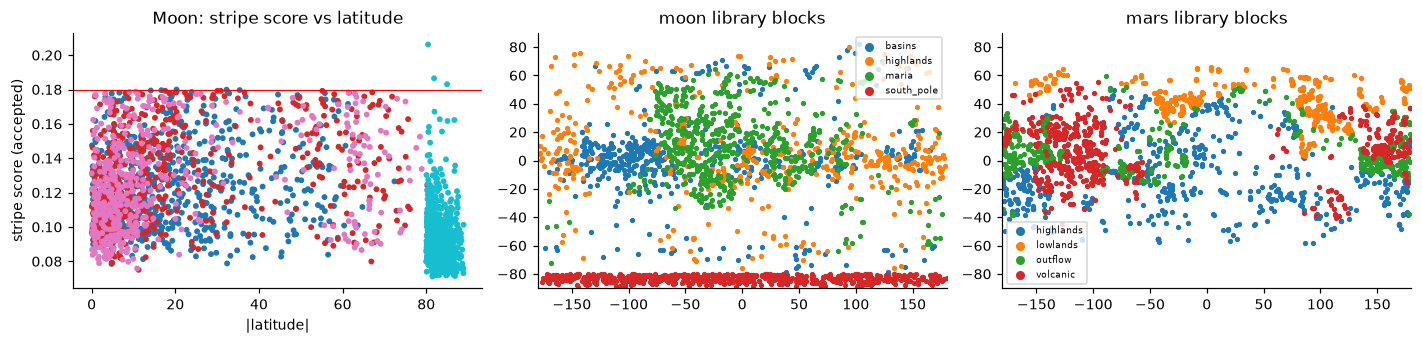

In [8]:
rows = []
for (w, r), idx in pd.Series(range(len(lib["world"]))).groupby([lib["world"], lib["region"]]):
    i = idx.values
    per_dtm = Counter(lib["href"][i])
    rows.append(dict(world=w, region=r, blocks=len(i), tagged=int((lib["tag"][i] != "background").sum()),
                     groups=len(set(lib["group"][i])), source_dtms=len(per_dtm), most_blocks_one_dtm=max(per_dtm.values()),
                     lat_min=lib["lat"][i].min(), lat_max=lib["lat"][i].max(), native_m=np.median(lib["native_m"][i])))
d5 = pd.DataFrame(rows)
display(d5)
SUMMARY["blocks in moon:south_pole"] = (int(d5[(d5.world == "moon") & (d5.region == "south_pole")]["blocks"].sum()), "aim 600 at v1")
SUMMARY["fewest blocks in a Mars region"] = (int(d5[d5.world == "mars"]["blocks"].min()), "aim 600 at v1")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
m = lib["world"] == "moon"
axes[0].scatter(np.abs(lib["lat"][m]), lib["stripe"][m], s=8, c=pd.factorize(lib["region"][m])[0], cmap="tab10")
axes[0].axhline(0.18, color="r", lw=0.8); axes[0].set_xlabel("|latitude|"); axes[0].set_ylabel("stripe score (accepted)")
axes[0].set_title("Moon: stripe score vs latitude")
for ax, w in zip(axes[1:], rt.WORLDS):
    m = lib["world"] == w
    for r in np.unique(lib["region"][m]):
        mm = m & (lib["region"] == r)
        ax.scatter(lib["lon"][mm], lib["lat"][mm], s=6, label=r)
    ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_title(f"{w} library blocks"); ax.legend(fontsize=6, markerscale=2)
plt.tight_layout(); plt.show()

## D6. How noisy the smoke scores are

A region score is "better than x% of the region's own blocks", so with n calibration blocks it can only move in steps of about 100/(n+1). Then the featured sites are re-scored with the calibration lists bootstrapped 200 times, which shows how much each score would wobble just from which blocks happened to be in the library.

In [9]:
rows = []
for r, key in enumerate(model.region_keys):
    for s in SCALES:
        n = len(model.calib[s][r])
        rows.append(dict(region=key, scale=s, calib_blocks=n, score_step=100 / (n + 1), top_k=rt.top_k_for(model, len(model.members[r]))))
display(pd.DataFrame(rows).pivot(index="region", columns="scale", values=["calib_blocks", "score_step", "top_k"]))


def emb_of(i):
    out = {}
    for s in SCALES:
        t = tok[s]["earth"][i].astype(np.float64)
        out[s] = (t, blk[s]["earth"][i], pca(s, sk(t[None]))[0])
    return out


def boot(res_region, r, n_boot=200, seed=0):
    g = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        L = model.combo_bias
        for s, v in res_region["scales"].items():
            cal = model.calib[s][r]
            cb = np.sort(g.choice(cal, len(cal), replace=True))
            L += model.S[s]["weight"] * rt.to_logit(100 * rt.calibrated(cb, v["aggregate"]))
        out.append(100 * expit(L))
    return np.percentile(out, [5, 95])


rows = []
for i in np.flatnonzero((env["set"] == "featured").values):
    emb = emb_of(i)
    for w in rt.WORLDS:
        for res in rt.region_scores(model, emb, w):
            lo, hi = boot(res, res["region_id"])
            rows.append(dict(site=env["name"][i], region=res["region"], score=res["score"], lo90=lo, hi90=hi, width=hi - lo))
d6 = pd.DataFrame(rows)
display(d6.groupby("region")["width"].median().rename("median 90% width (score points)").to_frame())
SUMMARY["median 90% wobble of a region score"] = (d6["width"].median(), "points; should shrink a lot at v1")
d6.pivot(index="site", columns="region", values="score").round(0)

calib_blocks        score_step           top_k      
scale               regional   site   regional   site regional  site
region                                                              
mars:highlands         150.0  150.0      0.662  0.662     25.0  25.0
mars:lowlands          150.0  150.0      0.662  0.662     25.0  25.0
mars:outflow           150.0  150.0      0.662  0.662     25.0  25.0
mars:volcanic          150.0  150.0      0.662  0.662     25.0  25.0
moon:basins            150.0  150.0      0.662  0.662     25.0  25.0
moon:highlands         150.0  150.0      0.662  0.662     25.0  25.0
moon:maria             150.0  150.0      0.662  0.662     25.0  25.0
moon:south_pole        150.0  150.0      0.662  0.662     25.0  25.0

,median 90% width (score points)
region,
mars:highlands,4.853
mars:lowlands,5.917
mars:outflow,4.973
mars:volcanic,4.719
moon:basins,5.861
moon:highlands,5.038
moon:maria,5.117
moon:south_pole,3.492


region,mars:highlands,mars:lowlands,mars:outflow,mars:volcanic,moon:basins,moon:highlands,moon:maria,moon:south_pole
site,,,,,,,,
Amazon rainforest,27.0,50.0,53.0,56.0,19.0,20.0,55.0,19.0
Dutch farmland,24.0,36.0,37.0,45.0,19.0,19.0,47.0,19.0
Haughton crater,49.0,34.0,43.0,43.0,33.0,52.0,46.0,22.0
Himalayan ridge,22.0,20.0,22.0,21.0,20.0,22.0,19.0,21.0
Holuhraun lava field,71.0,42.0,57.0,65.0,23.0,80.0,65.0,31.0
Lanzarote Timanfaya,55.0,35.0,54.0,47.0,24.0,71.0,55.0,24.0
McMurdo Dry Valleys,23.0,23.0,38.0,23.0,72.0,55.0,29.0,35.0
Meteor Crater,47.0,40.0,68.0,49.0,19.0,32.0,76.0,19.0
Utah near MDRS,48.0,32.0,54.0,45.0,38.0,69.0,54.0,31.0


## D7. Correlated features

Spearman correlation between per-block feature summaries (mean of each token feature over the 64 cells, plus the block features), over the library and random Earth land. Pairs above 0.9 split credit between them in the pair model and are candidates to merge or drop.

site: 6 pairs above 0.9
    depression_area ~ depression_depth +0.97
         slope_mean ~ shadow_mid       +0.94
        geo_concave ~ shadow_low       +0.94
         slope_mean ~ relief           +0.94
         slope_mean ~ shadow_low       +0.93
         slope_mean ~ geo_concave      +0.90


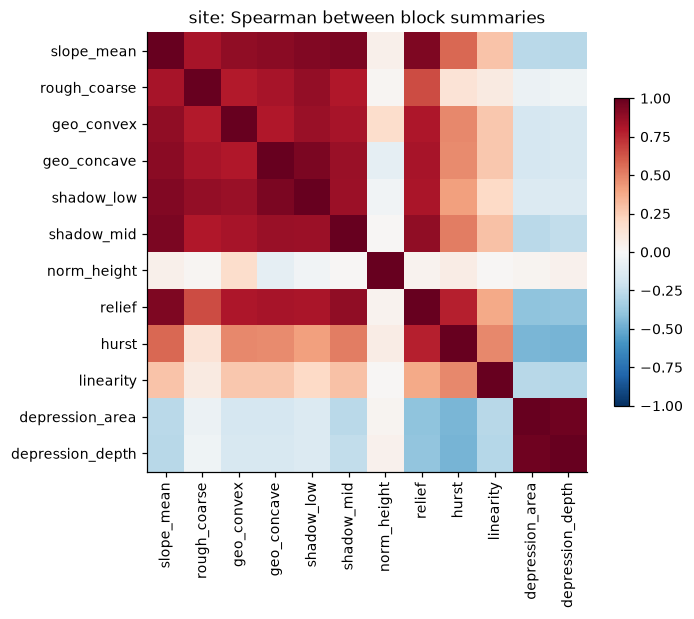

regional: 10 pairs above 0.9
         slope_mean ~ rough_coarse     +0.98
         slope_mean ~ shadow_mid       +0.98
       rough_coarse ~ shadow_low       +0.97
       rough_coarse ~ shadow_mid       +0.96
    depression_area ~ depression_depth +0.96
         slope_mean ~ shadow_low       +0.96
         shadow_low ~ shadow_mid       +0.96
         slope_mean ~ relief           +0.95
         shadow_mid ~ relief           +0.94
        geo_concave ~ shadow_low       +0.91


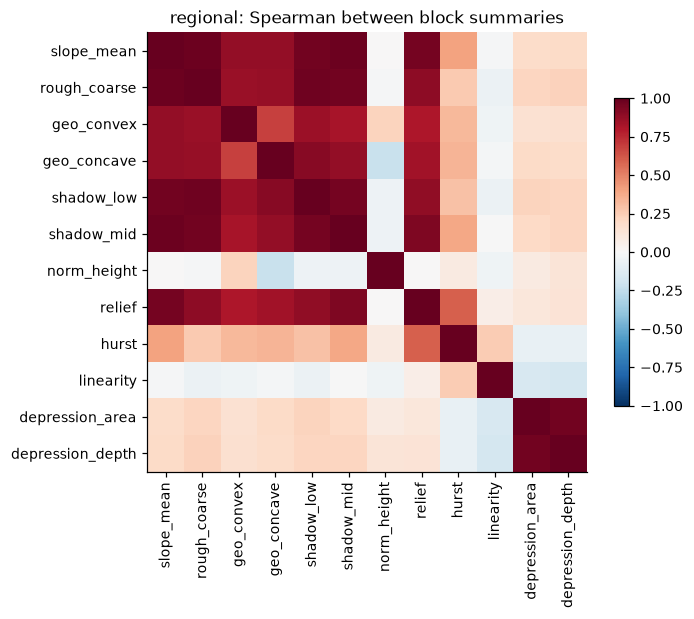

In [10]:
for s in SCALES:
    T = np.concatenate([lib_all(tok[s]), tok[s]["earth"][RAND]]).mean(1)
    Bk = np.concatenate([lib_all(blk[s]), blk[s]["earth"][RAND]])
    df = pd.DataFrame(np.c_[T, Bk], columns=F + B)
    rho = df.corr(method="spearman")
    pairs = [(a, b, rho.loc[a, b]) for i, a in enumerate(rho.index) for b in rho.columns[i + 1:] if abs(rho.loc[a, b]) > 0.9]
    print(f"{s}: {len(pairs)} pairs above 0.9")
    for a, b, v in sorted(pairs, key=lambda x: -abs(x[2])):
        print(f"   {a:>16} ~ {b:<16} {v:+.2f}")
    plt.figure(figsize=(6.5, 5.5)); plt.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
    plt.xticks(range(len(rho)), rho.columns, rotation=90); plt.yticks(range(len(rho)), rho.index)
    plt.colorbar(shrink=0.7); plt.title(f"{s}: Spearman between block summaries"); plt.tight_layout(); plt.show()

## D8. Why analog sites rank badly on landscape

Scores every random, analog and featured Earth block through the real runtime (`rt.region_scores`, both scales) and takes its best region logit across both worlds. Then: where analog sites rank among random land (0% = top, 50% = chance), per region too, and which pair-model inputs pull analog sites down compared with random land. Takes a couple of minutes.

  100/2565 scored, 251s


  200/2565 scored, 281s


  300/2565 scored, 312s


  400/2565 scored, 342s


  500/2565 scored, 372s


  600/2565 scored, 400s


... (20 outputs left out)

/var/folders/t0/mtw80r2115v6pd9wky_yrfzh0000gn/T/ipykernel_86334/3526972533.py:14: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  L["best"] = L[keys].max(1)


,region,median_rank,top10
0,best of all,0.551,0.071
1,moon:maria,0.711,0.054
2,moon:highlands,0.106,0.500
3,moon:basins,0.267,0.161
4,moon:south_pole,0.118,0.446
5,mars:highlands,0.238,0.321
6,mars:lowlands,0.712,0.018
7,mars:volcanic,0.663,0.018
8,mars:outflow,0.629,0.018


,"analog minus random, logit points (best match)"
slope_mean,-0.030
shadow_low,-0.018
geo_concave,-0.016
d_linearity,-0.001
rough_coarse,0.000
geo_convex,0.000
shadow_mid,0.000
norm_height,0.000
d_hurst,0.003
d_depression_depth,0.004


,"analog minus random, site tokens (IQR units) / block ratio"
slope_mean,0.337
rough_coarse,0.367
geo_convex,0.156
geo_concave,0.211
shadow_low,0.291
shadow_mid,0.587
norm_height,-0.139
relief (ratio),3.844
hurst (ratio),1.072
linearity (ratio),1.179


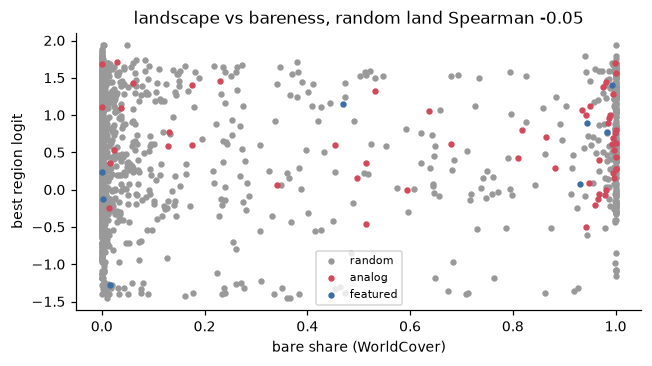

In [11]:
t0 = time.time()
idx = np.flatnonzero(env["set"].isin(["random", "analog", "featured"]).values)
REG = {}
for n, i in enumerate(idx, 1):
    emb = emb_of(i)
    REG[i] = {w: rt.region_scores(model, emb, w) for w in rt.WORLDS}
    if n % 100 == 0:
        print(f"  {n}/{len(idx)} scored, {time.time() - t0:.0f}s")
print(f"scored {len(idx)} blocks in {time.time() - t0:.0f}s")

keys = [k for k in model.region_keys]
L = pd.DataFrame({k: [next((r["logit"] for w in rt.WORLDS for r in REG[i][w] if r["region"] == k), np.nan) for i in idx] for k in keys},
                 index=idx)
L["best"] = L[keys].max(1)
sets = env["set"].values[idx]


def rank_among_random(col):
    rv = L[col][sets == "random"].dropna().values
    av = L[col][sets == "analog"].dropna().values
    return np.array([(rv > a).mean() for a in av])


rows = [dict(region="best of all", median_rank=np.median(rank_among_random("best")), top10=np.mean(rank_among_random("best") < 0.1))]
for k in keys:
    if L[k].notna().sum() > 10:
        rr = rank_among_random(k)
        rows.append(dict(region=k, median_rank=np.median(rr), top10=np.mean(rr < 0.1)))
d8 = pd.DataFrame(rows)
display(d8)
SUMMARY["analog sites, landscape median rank"] = (d8.iloc[0]["median_rank"], "0% top, 50% chance; aim < 0.3")

contrib = {}
for i in idx:
    best_w = max(rt.WORLDS, key=lambda w: REG[i][w][0]["logit"])
    contrib[i] = REG[i][best_w][0]["best"][0]["contributions"]
C = pd.DataFrame.from_dict(contrib, orient="index")
diff = (C[sets == "analog"].mean() - C[sets == "random"].mean()).sort_values()
tdiff = pd.Series(np.r_[tok["site"]["earth"][idx][sets == "analog"].mean((0, 1)) - tok["site"]["earth"][idx][sets == "random"].mean((0, 1)),
                        np.nanmedian(blk["site"]["earth"][idx][sets == "analog"], 0) / np.nanmedian(blk["site"]["earth"][idx][sets == "random"], 0)],
                  index=F + [f"{b} (ratio)" for b in B])
display(pd.DataFrame({"analog minus random, logit points (best match)": diff}))
display(pd.DataFrame({"analog minus random, site tokens (IQR units) / block ratio": tdiff}))

fig, ax = plt.subplots(1, 1, figsize=(6, 3.4))
for st, c in (("random", "#999"), ("analog", "#d1495b"), ("featured", "#3a6ea5")):
    m = sets == st
    ax.scatter(env["bare"].values[idx][m], L["best"].values[m], s=10, c=c, label=st)
ax.set_xlabel("bare share (WorldCover)"); ax.set_ylabel("best region logit"); ax.legend(fontsize=7)
rho = spearmanr(env["bare"].values[idx][sets == "random"], L["best"].values[sets == "random"], nan_policy="omit")[0]
ax.set_title(f"landscape vs bareness, random land Spearman {rho:+.2f}"); plt.tight_layout(); plt.show()

## D9. Analog-site coordinates that look wrong

The 61 analog sites were typed from memory. A real field site is usually bare and dry, so a block that's mostly trees, crops, buildings or water is a sign the coordinates are off. Also lists sites within 10 km of each other (duplicates) and the site's relief (a few metres usually means the block missed the feature).

In [12]:
a = env[env["set"] == "analog"].copy()
a["relief_m"] = E["block_site"][a.index, 0]
lat, lon = np.radians(a["lat"].values), np.radians(a["lon"].values)
d = 6371 * 2 * np.arcsin(np.sqrt(np.sin((lat[:, None] - lat[None]) / 2) ** 2
                                 + np.cos(lat[:, None]) * np.cos(lat[None]) * np.sin((lon[:, None] - lon[None]) / 2) ** 2))
np.fill_diagonal(d, np.inf)
a["nearest_site_km"] = d.min(1)
flags = []
for _, r in a.iterrows():
    f = [n for n, t in (("tree", 0.3), ("crop", 0.2), ("built", 0.1), ("water", 0.2)) if (r[n] if pd.notna(r[n]) else 0) > t]
    if pd.isna(r["bare"]):
        f.append("no land cover")
    if r["relief_m"] < 10:
        f.append("relief < 10 m")
    if r["nearest_site_km"] < 10:
        f.append("duplicate < 10 km")
    flags.append(", ".join(f))
a["flags"] = flags
SUMMARY["analog sites flagged"] = (int((a["flags"] != "").sum()), "of 61; check these first")
print(f"{(a['flags'] != '').sum()} of {len(a)} sites flagged")
a[a["flags"] != ""][["name", "lat", "lon", "tree", "crop", "built", "water", "bare", "precip", "relief_m", "nearest_site_km", "flags"]]

0 of 56 sites flagged


,name,lat,lon,tree,crop,built,water,bare,precip,relief_m,nearest_site_km,flags


## Summary

In [13]:
pd.DataFrame([(k, v[0], v[1]) for k, v in SUMMARY.items()], columns=["check", "value", "how to read"])

,check,value,how to read
0,"planet check, site",0.699,0.33 blind; aim < 0.5
1,"planet check, regional",0.678,0.33 blind; aim < 0.5
2,"planet check site, bare Earth only",0.734,big drop vs all = FABDEM helps
3,"planet check regional, bare Earth only",0.676,big drop vs all = FABDEM helps
4,blocks in moon:south_pole,600.000,aim 600 at v1
5,fewest blocks in a Mars region,600.000,aim 600 at v1
6,median 90% wobble of a region score,5.006,points; should shrink a lot at v1
7,"analog sites, landscape median rank",0.551,"0% top, 50% chance; aim < 0.3"
8,analog sites flagged,0.000,of 61; check these first
